In [3]:
def alg1(data):
    data = list(data)
    changes = True
    while changes:
        changes = False
        for i in range(len(data) - 1):
            if data[i + 1] < data[i]:
                data[i], data[i + 1] = data[i + 1], data[i]
                changes = True
    return data


def alg2(data):
    if len(data) <= 1:
        return data
    else:
        split = len(data) // 2
        left = iter(alg2(data[:split]))
        right = iter(alg2(data[split:]))
        result = []
        left_top = next(left)
        right_top = next(right)
        while True:
            if left_top < right_top:
                result.append(left_top)
                try:
                    left_top = next(left)
                except StopIteration:
                    return result + [right_top] + list(right)
            else:
                result.append(right_top)
                try:
                    right_top = next(right)
                except StopIteration:
                    return result + [left_top] + list(left)

In [ ]:
import numpy as np

def data1(n, sigma=10, rho=28, beta=8 / 3, dt=0.01, x=1, y=1, z=1):
    state = np.array([x, y, z], dtype=float)
    result = []
    for _ in range(n):
        x, y, z = state
        state += dt * np.array(
            [sigma * (y - x), x * (rho - z) - y, x * y - beta * z]
        )
        result.append(float(state[0] + 30))
    return result

def data2(n):
    return list(range(n))

def data3(n):
    return list(range(n, 0, -1))


In [4]:
n = 8

test_cases = [
    ("data1", data1(n)),
    ("data2", data2(n)),
    ("data3", data3(n)),
]

for case_name, test_input in test_cases:
    output1 = alg1(test_input.copy())
    output2 = alg2(test_input.copy())
    expected = sorted(test_input)

    print(f"Case: {case_name}")
    print("Input:   ", test_input)
    print("alg1:    ", output1)
    print("alg2:    ", output2)
    print("Both correct:", output1 == expected and output2 == expected)
    print("-" * 50)

Case: data1
Input:    [31.0, 31.026, 31.07515666666667, 31.1456131764, 31.236317170692352, 31.346883543428103, 31.477492347868477, 31.628814213217787]
alg1:     [31.0, 31.026, 31.07515666666667, 31.1456131764, 31.236317170692352, 31.346883543428103, 31.477492347868477, 31.628814213217787]
alg2:     [31.0, 31.026, 31.07515666666667, 31.1456131764, 31.236317170692352, 31.346883543428103, 31.477492347868477, 31.628814213217787]
Both correct: True
--------------------------------------------------
Case: data2
Input:    [0, 1, 2, 3, 4, 5, 6, 7]
alg1:     [0, 1, 2, 3, 4, 5, 6, 7]
alg2:     [0, 1, 2, 3, 4, 5, 6, 7]
Both correct: True
--------------------------------------------------
Case: data3
Input:    [8, 7, 6, 5, 4, 3, 2, 1]
alg1:     [1, 2, 3, 4, 5, 6, 7, 8]
alg2:     [1, 2, 3, 4, 5, 6, 7, 8]
Both correct: True
--------------------------------------------------


algorithm         alg1      alg2
dataset n                       
data1   100   0.000354  0.000093
        153   0.000950  0.000143
        235   0.002450  0.000222
        360   0.003963  0.000352
        553   0.008912  0.000567
        848   0.034385  0.000884
        1301  0.078235  0.001403
        1995  0.188416  0.002196
data2   100   0.000004  0.000084
        153   0.000006  0.000129
        235   0.000008  0.000208
        360   0.000014  0.000328
        553   0.000022  0.000518
        848   0.000034  0.000809
        1301  0.000054  0.001241
        1995  0.000084  0.001924
data3   100   0.000519  0.000086
        153   0.001204  0.000134
        235   0.002762  0.000208
        360   0.007162  0.000332
        553   0.017549  0.000526
        848   0.042771  0.000806
        1301  0.102376  0.001250
        1995  0.242207  0.001907

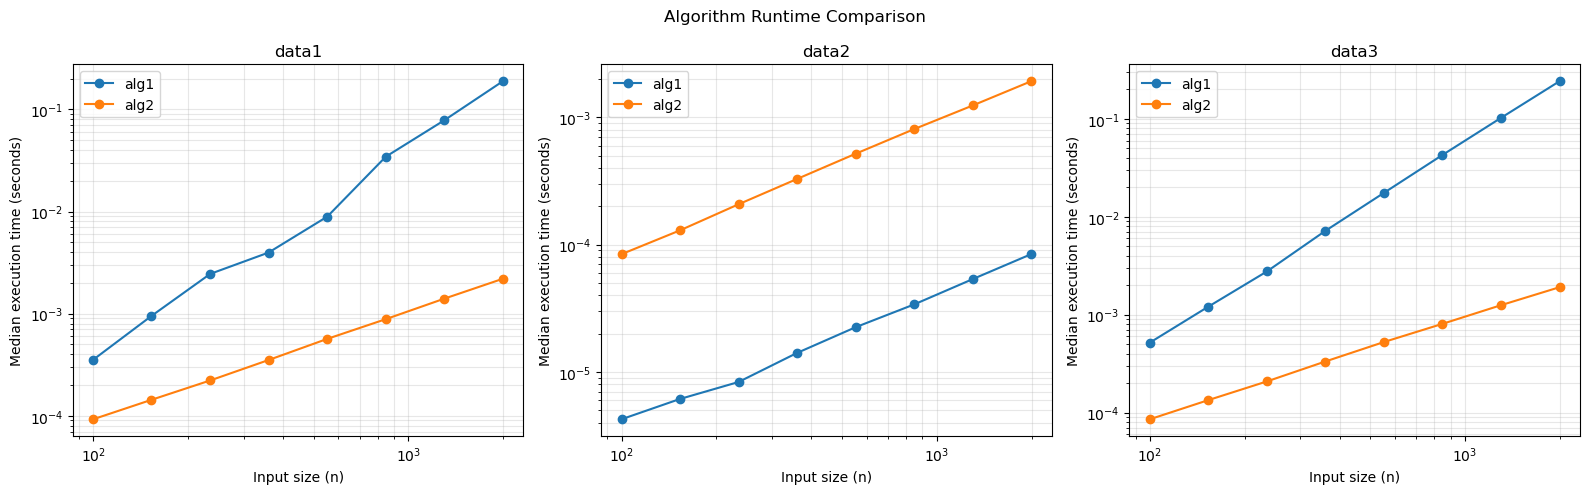

,dataset,algorithm,estimated_slope
0,data1,alg1,2.079412
1,data1,alg2,1.062627
2,data2,alg1,1.013919
3,data2,alg2,1.050273
4,data3,alg1,2.069037
5,data3,alg2,1.041350


In [5]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Start with moderate sizes because alg1 can be slow.
sizes = np.unique(np.logspace(2, 3.3, num=8).astype(int))
repeats = 5

generators = {
    "data1": data1,
    "data2": data2,
    "data3": data3,
}

algorithms = {
    "alg1": alg1,
    "alg2": alg2,
}

records = []

for data_name, generator in generators.items():
    for n in sizes:
        # Generate the same input for both algorithms outside timing.
        test_data = generator(int(n))
        expected = sorted(test_data)

        timings = {name: [] for name in algorithms}

        # Warm up each algorithm outside timing.
        for algorithm in algorithms.values():
            assert algorithm(test_data.copy()) == expected

        for repeat in range(repeats):
            # Alternate execution order to reduce order effects.
            order = list(algorithms.items())
            if repeat % 2 == 1:
                order.reverse()

            for algorithm_name, algorithm in order:
                input_copy = test_data.copy()

                start = time.perf_counter()
                result = algorithm(input_copy)
                elapsed = time.perf_counter() - start

                # Check correctness outside timing.
                assert result == expected

                timings[algorithm_name].append(elapsed)

        for algorithm_name, measured_times in timings.items():
            records.append({
                "dataset": data_name,
                "n": int(n),
                "algorithm": algorithm_name,
                "median_seconds": float(np.median(measured_times)),
            })

results = pd.DataFrame(records)

display(
    results.pivot(
        index=["dataset", "n"],
        columns="algorithm",
        values="median_seconds",
    )
)

# Plot one panel for each data generator.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, data_name in zip(axes, generators):
    for algorithm_name in algorithms:
        subset = results[
            (results["dataset"] == data_name)
            & (results["algorithm"] == algorithm_name)
        ].sort_values("n")

        ax.loglog(
            subset["n"],
            subset["median_seconds"],
            marker="o",
            label=algorithm_name,
        )

    ax.set_title(data_name)
    ax.set_xlabel("Input size (n)")
    ax.set_ylabel("Median execution time (seconds)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

fig.suptitle("Algorithm Runtime Comparison")
plt.tight_layout()
plt.show()

# Estimate the slope over the measured range.
slope_records = []

for data_name in generators:
    for algorithm_name in algorithms:
        subset = results[
            (results["dataset"] == data_name)
            & (results["algorithm"] == algorithm_name)
        ].sort_values("n")

        slope, intercept = np.polyfit(
            np.log10(subset["n"]),
            np.log10(subset["median_seconds"]),
            deg=1,
        )

        slope_records.append({
            "dataset": data_name,
            "algorithm": algorithm_name,
            "estimated_slope": slope,
        })

slopes = pd.DataFrame(slope_records)
display(slopes)